In [1]:
from __future__ import print_function
import sys, os
import numpy as np
import pandas as pd
import pickle
import matplotlib.pyplot as plt
from matplotlib.backends.backend_pdf import PdfPages
from collections import defaultdict
import multiprocessing

import ROOT
from ROOT import gROOT, gStyle, gDirectory, gPad
nthreads = min(4, max(1, multiprocessing.cpu_count()-1))  # tune as needed
ROOT.EnableImplicitMT(nthreads)


In [2]:
# POTs for resampler 
nPOT = 1.0e12

VDresampler_dict = {
    'Ele_stmedep00': {
        'file': '/exp/mu2e/data/users/yongyiwu/stmedep00/datasets/stmedep/rootfiles/hole_50_50_VD101_Ele_dump.root',
        'POTs' : nPOT,
    },
    'Mu_stmedep00': {
        'file': '/exp/mu2e/data/users/yongyiwu/stmedep00/datasets/stmedep/rootfiles/hole_50_50_VD101_Mu_dump.root',
        'POTs' : nPOT,
    },
    '1809_stmedep00': {
        'file': '/exp/mu2e/data/users/yongyiwu/stmedep00/datasets/stmedep/rootfiles/hole_50_50_VD101_1809_dump.root',
        'POTs' : nPOT,
    },
    'Neutrals_stmedep00': {
        'file': '/exp/mu2e/data/users/yongyiwu/stmedep00/datasets/stmedep/rootfiles/hole_50_50_VD101_Neutrals_dump.root',
        'POTs' : nPOT,
    },

    'Ele_stmedep01': {
        'file': '/exp/mu2e/data/users/yongyiwu/stmedep01/datasets/stmedep/rootfiles/hole_100_100_VD101_Ele_dump.root',
        'POTs' : nPOT,
    },
    'Mu_stmedep01': {
        'file': '/exp/mu2e/data/users/yongyiwu/stmedep01/datasets/stmedep/rootfiles/hole_100_100_VD101_Mu_dump.root',
        'POTs' : nPOT,
    },
    '1809_stmedep01': {
        'file': '/exp/mu2e/data/users/yongyiwu/stmedep01/datasets/stmedep/rootfiles/hole_100_100_VD101_1809_dump.root',
        'POTs' : nPOT,
    },
    'Neutrals_stmedep01': {
        'file': '/exp/mu2e/data/users/yongyiwu/stmedep01/datasets/stmedep/rootfiles/hole_100_100_VD101_Neutrals_dump.root',
        'POTs' : nPOT,
    },

    'Ele_stmedep02': {
        'file': '/exp/mu2e/data/users/yongyiwu/stmedep02/datasets/stmedep/rootfiles/hole_200_200_VD101_Ele_dump.root',
        'POTs' : nPOT,
    },
    'Mu_stmedep02': {
        'file': '/exp/mu2e/data/users/yongyiwu/stmedep02/datasets/stmedep/rootfiles/hole_200_200_VD101_Mu_dump.root',
        'POTs' : nPOT,
    },
    '1809_stmedep02': {
        'file': '/exp/mu2e/data/users/yongyiwu/stmedep02/datasets/stmedep/rootfiles/hole_200_200_VD101_1809_dump.root',
        'POTs' : nPOT,
    },
    'Neutrals_stmedep02': {
        'file': '/exp/mu2e/data/users/yongyiwu/stmedep02/datasets/stmedep/rootfiles/hole_200_200_VD101_Neutrals_dump.root',
        'POTs' : nPOT,
    },

    'Ele_stmedep03': {
        'file': '/exp/mu2e/data/users/yongyiwu/stmedep03/datasets/stmedep/rootfiles/hole_400_400_VD101_Ele_dump.root',
        'POTs' : nPOT,
    },
    'Mu_stmedep03': {
        'file': '/exp/mu2e/data/users/yongyiwu/stmedep03/datasets/stmedep/rootfiles/hole_400_400_VD101_Mu_dump.root',
        'POTs' : nPOT,
    },
    '1809_stmedep03': {
        'file': '/exp/mu2e/data/users/yongyiwu/stmedep03/datasets/stmedep/rootfiles/hole_400_400_VD101_1809_dump.root',
        'POTs' : nPOT,
    },
    'Neutrals_stmedep03': {
        'file': '/exp/mu2e/data/users/yongyiwu/stmedep03/datasets/stmedep/rootfiles/hole_400_400_VD101_Neutrals_dump.root',
        'POTs' : nPOT,
    },

    'Ele_stmedep04': {
        'file': '/exp/mu2e/data/users/yongyiwu/stmedep04/datasets/stmedep/rootfiles/hole_0_0_VD101_Ele_dump.root',
        'POTs' : nPOT,
    },
    'Mu_stmedep04': {
        'file': '/exp/mu2e/data/users/yongyiwu/stmedep04/datasets/stmedep/rootfiles/hole_0_0_VD101_Mu_dump.root',
        'POTs' : nPOT,
    },
    '1809_stmedep04': {
        'file': '/exp/mu2e/data/users/yongyiwu/stmedep04/datasets/stmedep/rootfiles/hole_0_0_VD101_1809_dump.root',
        'POTs' : nPOT,
    },
    'Neutrals_stmedep04': {
        'file': '/exp/mu2e/data/users/yongyiwu/stmedep04/datasets/stmedep/rootfiles/hole_0_0_VD101_Neutrals_dump.root',
        'POTs' : nPOT,
    },
}

# MC truth of upstream dataset to VD101
MCTruth_dict = {
    "Ele_Beam1a":{
        "file": "tmp/ele101_MDC2025ai_dump.root",
        "POTs": 98360017778.32725, # dts.mu2e.STMBeamToVDEle116.MDC2025ai.art    : 5441845688 / 5532579  * 1e8
    },
    "Mu_Beam1a":{
        "file": "tmp/mu101_MDC2025ai_dump2.root",
        "POTs": 467691847195.7197, # dts.mu2e.STMBeamToVDMu116.MDC2025ai.art     : 1e9        / 213816   * 1e8
    },
    "1809_Beam1a":{
         "file": "tmp/tgtstps101_MDC2025au_dump.root",
        "POTs": 5186958594225.648, # dts.mu2e.STM1809ToVD116.MDC2025au.art       : 4e9     / 1442670/1e3 * 4e9 / 213816  * 1e8
    },
    "Neutrals_Beam1a":{
        "file": "tmp/neutrals101_MDC2025av_dump.root",
        "POTs": 3743491962.619810  # dts.mu2e.STMNeutralsToVD116Cat.MDC2025av.art: 2000000000 / 53426053 * 1e8
    },
}

In [3]:
pdg_groups = {
    "e-"      : 11,
    "gamma"   : 22,
    "e+"      : -11,
    "neutron" : 2112,
}
pdg_colors = {
    "e-"      : ROOT.kRed + 1,
    "gamma"   : ROOT.kOrange + 1,
    "e+"      : ROOT.kBlue + 1,
    "neutron" : ROOT.kGreen + 2,
    "other"   : ROOT.kGray + 1,
}
campaign_order = [
    "Beam1a",
    "stmedep00",
    "stmedep01",
    "stmedep02",
    "stmedep03",
    "stmedep04",
]
campaign_colors = {
    "Beam1a"   : ROOT.kBlack,
    "stmedep00": ROOT.kRed+1,
    "stmedep01": ROOT.kBlue+1,
    "stmedep02": ROOT.kGreen+2,
    "stmedep03": ROOT.kOrange+7,
    "stmedep04": ROOT.kMagenta+1,
}
# --------------------------------------------------
# Merge dictionaries
# --------------------------------------------------
samples = {}
samples.update(VDresampler_dict)
samples.update(MCTruth_dict)
# --------------------------------------------------
# Categorize samples
# --------------------------------------------------
categories = ["Ele", "Mu", "1809", "Neutrals"]
sample_groups = defaultdict(dict)
for name, info in samples.items():
    for cat in categories:
        if name.startswith(cat):
            sample_groups[cat][name] = info
            break
# --------------------------------------------------
# normalization
# --------------------------------------------------
norm_weights = {}
for cat in categories:
    targetPOT = min(
        sample_groups[cat][s]["POTs"]
        for s in sample_groups[cat]
    )
    print(cat, "target POT =", targetPOT)
    for s in sample_groups[cat]:
        norm_weights[s] = (targetPOT / sample_groups[cat][s]["POTs"])
        print(f"  {s:20s}", f"weight={norm_weights[s]:.5g}")

Ele target POT = 98360017778.32726
  Ele_stmedep00        weight=0.09836
  Ele_stmedep01        weight=0.09836
  Ele_stmedep02        weight=0.09836
  Ele_stmedep03        weight=0.09836
  Ele_stmedep04        weight=0.09836
  Ele_Beam1a           weight=1
Mu target POT = 467691847195.7197
  Mu_stmedep00         weight=0.46769
  Mu_stmedep01         weight=0.46769
  Mu_stmedep02         weight=0.46769
  Mu_stmedep03         weight=0.46769
  Mu_stmedep04         weight=0.46769
  Mu_Beam1a            weight=1
1809 target POT = 1000000000000.0
  1809_stmedep00       weight=1
  1809_stmedep01       weight=1
  1809_stmedep02       weight=1
  1809_stmedep03       weight=1
  1809_stmedep04       weight=1
  1809_Beam1a          weight=0.19279
Neutrals target POT = 3743491962.61981
  Neutrals_stmedep00   weight=0.0037435
  Neutrals_stmedep01   weight=0.0037435
  Neutrals_stmedep02   weight=0.0037435
  Neutrals_stmedep03   weight=0.0037435
  Neutrals_stmedep04   weight=0.0037435
  Neutrals_Beam1

In [4]:
def draw_pdg_composition(category):

    stack = ROOT.THStack(f"stack_{category}", f"{category};Campaign;Normalized counts")
    legend = ROOT.TLegend(0.72, 0.65, 0.92, 0.90)

    # one histogram per PDG species
    hist_dict = {}

    for name in list(pdg_groups.keys()) + ["other"]:

        h = ROOT.TH1D(f"h_{category}_{name}", "", len(campaign_order), 0, len(campaign_order))
        for i, camp in enumerate(campaign_order, start=1):
            h.GetXaxis().SetBinLabel(i, camp)

        h.SetFillColor(pdg_colors[name])
        h.SetLineColor(ROOT.kBlack)

        hist_dict[name] = h

    # ------------------------------------
    # fill campaign bins
    # ------------------------------------

    for ibin, campaign in enumerate(campaign_order, start=1):
        sample = f"{category}_{campaign}"
        if sample not in sample_groups[category]:
            print(f"Missing sample: {sample}")
            continue

        df = (ROOT.RDataFrame("Stage1virtualdetector/ttree", sample_groups[category][sample]["file"]).Filter("pz > 0"))
        weight = norm_weights[sample]

        known_expr = []    
        for label, pdg in pdg_groups.items():
            n = (df.Filter(f"pdgId == {pdg}").Count().GetValue())
            print(f"{campaign:20s}", f"{label:8s}", n)

            hist_dict[label].SetBinContent(ibin,n * weight)
            hist_dict[label].SetBinError(ibin,(n**0.5) * weight)

            known_expr.append(f"pdgId == {pdg}")

        other_cut = "!(" + " || ".join(known_expr) + ")"

        n_other = (df.Filter(other_cut).Count().GetValue())
        hist_dict["other"].SetBinContent(ibin,n_other * weight)
        hist_dict["other"].SetBinError(ibin,(n_other**0.5) * weight)

    # ------------------------------------
    # draw
    # ------------------------------------

    # order of stacking
    stack_order = ["e-","e+","gamma","neutron","other"]

    for name in stack_order:
        stack.Add(hist_dict[name])
        legend.AddEntry(hist_dict[name],name,"f")

    c = ROOT.TCanvas(f"c_{category}",category,1200,800)

    stack.Draw("hist")
    legend.Draw("same")

    c.SetGridy()

    c.Modified()
    c.Update()

    return c

Beam1a               e-       4491
Beam1a               gamma    32318
Beam1a               e+       87
Beam1a               neutron  15
stmedep00            e-       30902
stmedep00            gamma    275812
stmedep00            e+       694
stmedep00            neutron  58
stmedep01            e-       30898
stmedep01            gamma    275808
stmedep01            e+       694
stmedep01            neutron  58
stmedep02            e-       30900
stmedep02            gamma    275804
stmedep02            e+       694
stmedep02            neutron  58
stmedep03            e-       30890
stmedep03            gamma    275809
stmedep03            e+       694
stmedep03            neutron  58
stmedep04            e-       30901
stmedep04            gamma    275810
stmedep04            e+       694
stmedep04            neutron  58


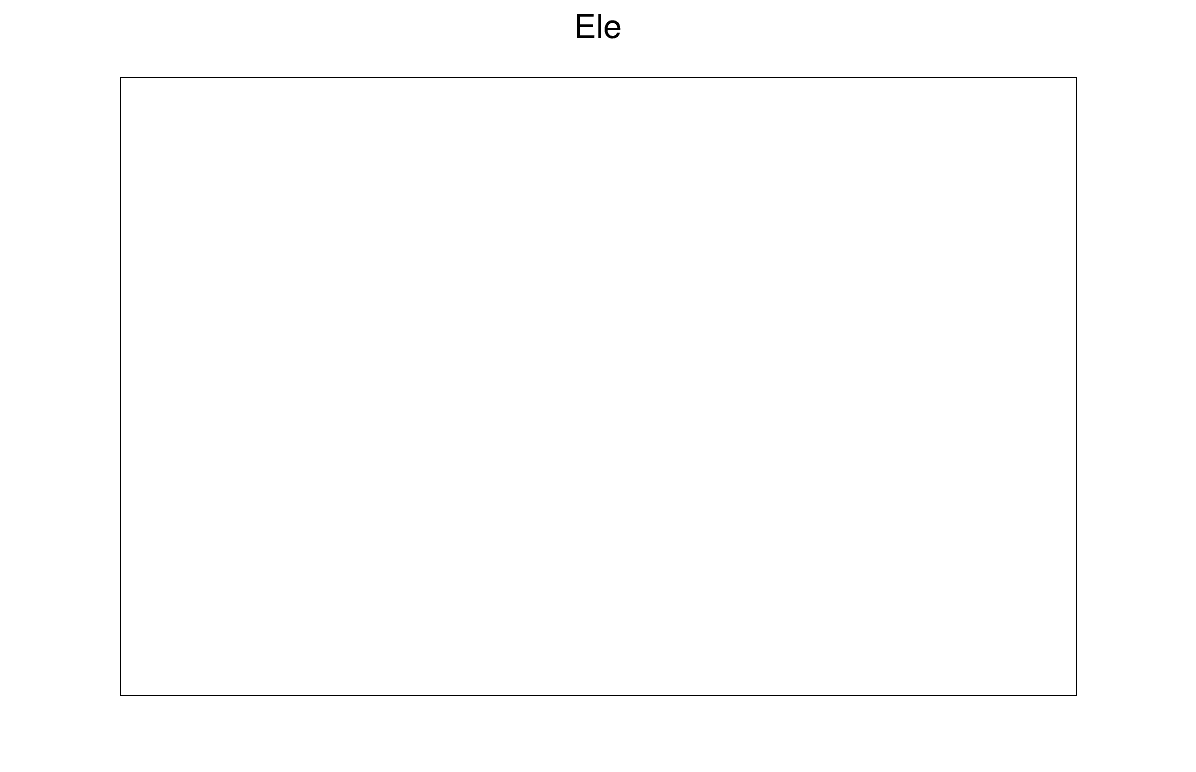

In [5]:
c = draw_pdg_composition("Ele")
c.Draw()